In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("FinancialMarketIntelligenceLab")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

FinancialMarketIntelligenceLab
Pandas version: 3.0.3
NumPy version: 2.4.6


# Bitcoin (BTC/USD) — Exploratory Data Analysis

## 1. Introduction

This notebook explores historical Bitcoin market data.

### Objectives
- Load and inspect historical data.
- Identify missing values and duplicate records.
- Clean and prepare the dataset.
- Analyze price changes and daily returns.
- Visualize historical price movements.

### Data Source
To be documented after selecting the dataset.

In [2]:
from pathlib import Path

data_path = Path("../data/raw/bitcoin-price-history.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

display(df.head())

Dataset shape: (4431, 2)

Column names: ['date', 'close_usd']


,date,close_usd
0,2014-09-17,457.33
1,2014-09-18,424.44
2,2014-09-19,394.80
3,2014-09-20,408.90
4,2014-09-21,398.82


In [3]:
# Inspect the dataset structure
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isna().sum())

# Check duplicate records
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Basic descriptive statistics
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4431 entries, 0 to 4430
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       4431 non-null   str    
 1   close_usd  4431 non-null   float64
dtypes: float64(1), str(1)
memory usage: 112.6 KB

Missing values:
date         0
close_usd    0
dtype: int64

Duplicate rows:
0


,close_usd
count,4431.000000
mean,30118.148416
std,32887.557001
min,178.100000
25%,3659.570000
50%,14699.200000
75%,52154.605000
max,124752.530000


In [4]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Sort observations chronologically
df = df.sort_values("date").reset_index(drop=True)

# Check date range
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check duplicate dates
print("\nDuplicate dates:", df["date"].duplicated().sum())

First date: 2014-09-17 00:00:00
Last date: 2026-11-03 00:00:00

Data types:
date         datetime64[us]
close_usd           float64
dtype: object

Duplicate dates: 0


In [5]:
# Generate a complete daily date range
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

# Find missing calendar dates
missing_dates = expected_dates.difference(
    pd.DatetimeIndex(df["date"])
)

print("Expected days:", len(expected_dates))
print("Actual observations:", len(df))
print("Missing calendar days:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nFirst missing dates:")
    print(missing_dates[:10])
else:
    print("\nNo missing calendar days.")

Expected days: 4431
Actual observations: 4431
Missing calendar days: 0

No missing calendar days.


## 2. Historical Bitcoin Price Visualization

This section visualizes Bitcoin's historical closing price in USD
to explore long-term trends and major price fluctuations.

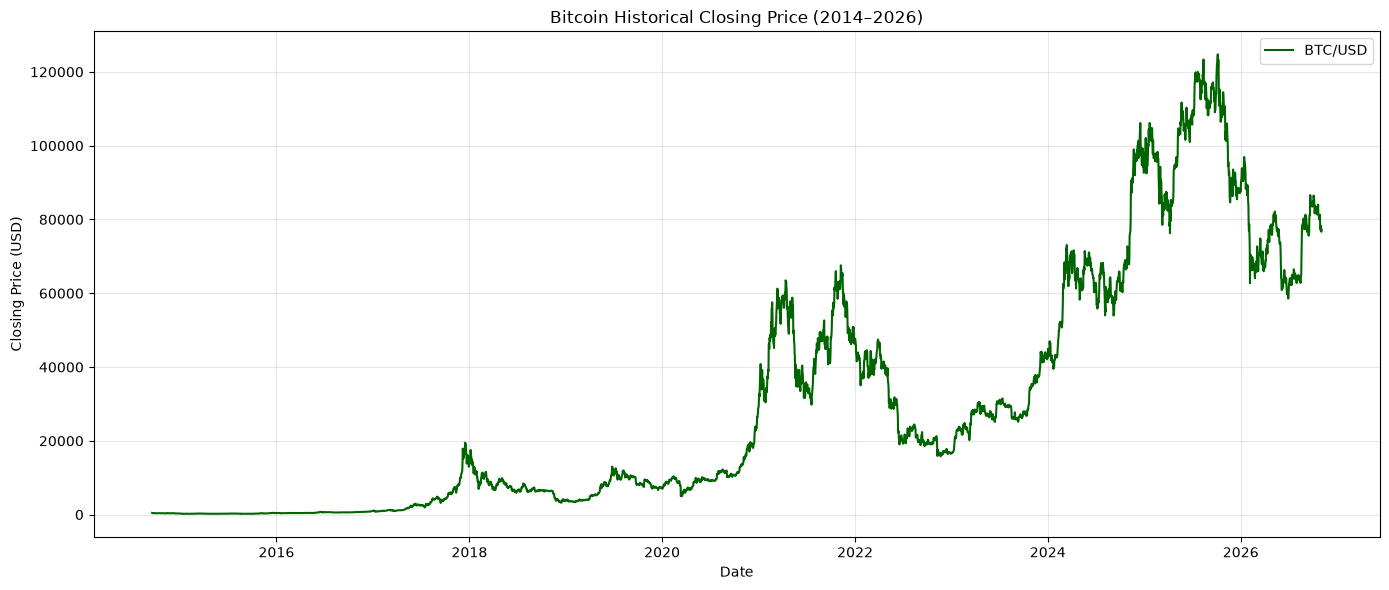

In [6]:
# Plot historical Bitcoin closing prices

plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["close_usd"],
    color="darkgreen",
    linewidth=1.5,
    label="BTC/USD"
)

plt.title("Bitcoin Historical Closing Price (2014–2026)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## 3. Daily Returns Analysis

Daily returns measure the percentage change in Bitcoin's closing
price compared with the previous day.

This analysis helps identify daily price fluctuations and provides
a foundation for measuring historical volatility.

In [7]:
# Calculate daily percentage returns
df["daily_return"] = df["close_usd"].pct_change() * 100

# Display the first observations
display(df.head(10))

# Descriptive statistics of daily returns
print("Daily Returns Statistics (%):")
display(df["daily_return"].describe())

,date,close_usd,daily_return
0,2014-09-17,457.33,NaN
1,2014-09-18,424.44,-7.191743
2,2014-09-19,394.80,-6.983319
3,2014-09-20,408.90,3.571429
4,2014-09-21,398.82,-2.465150
5,2014-09-22,402.15,0.834963
6,2014-09-23,435.79,8.365038
7,2014-09-24,423.21,-2.886711
8,2014-09-25,411.57,-2.750408
9,2014-09-26,404.43,-1.734820


Daily Returns Statistics (%):


count    4430.000000
mean        0.175736
std         3.449308
min       -37.169513
25%        -1.252293
50%         0.104466
75%         1.548290
max        25.247175
Name: daily_return, dtype: float64

In [8]:
# Load the documented Kaggle dataset

btc_path = Path("../data/raw/btc_1d_data_2018_to_2025.csv")
btc = pd.read_csv(btc_path)

print("Dataset shape:", btc.shape)
display(btc.head())
btc.info()

Dataset shape: (3089, 12)


,Open time,Open,High,Low,Close,Volume,Close time,Quote asset volume,Number of trades,Taker buy base asset volume,Taker buy quote asset volume,Ignore
0,2018-01-01 00:00:00.000000 UTC,13715.65,13818.55,12750.00,13380.00,8609.915844,2018-01-01 23:59:59.999000 UTC,1.147997e+08,105595,3961.938946,5.280975e+07,0
1,2018-01-02 00:00:00.000000 UTC,13382.16,15473.49,12890.02,14675.11,20078.092111,2018-01-02 23:59:59.999000 UTC,2.797171e+08,177728,11346.326739,1.580801e+08,0
2,2018-01-03 00:00:00.000000 UTC,14690.00,15307.56,14150.00,14919.51,15905.667639,2018-01-03 23:59:59.999000 UTC,2.361169e+08,162787,8994.953566,1.335873e+08,0
3,2018-01-04 00:00:00.000000 UTC,14919.51,15280.00,13918.04,15059.54,21329.649574,2018-01-04 23:59:59.999000 UTC,3.127816e+08,170310,12680.812951,1.861168e+08,0
4,2018-01-05 00:00:00.000000 UTC,15059.56,17176.24,14600.00,16960.39,23251.491125,2018-01-05 23:59:59.999000 UTC,3.693220e+08,192969,13346.622293,2.118299e+08,0


<class 'pandas.DataFrame'>
RangeIndex: 3089 entries, 0 to 3088
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Open time                     3089 non-null   str    
 1   Open                          3089 non-null   float64
 2   High                          3089 non-null   float64
 3   Low                           3089 non-null   float64
 4   Close                         3089 non-null   float64
 5   Volume                        3089 non-null   float64
 6   Close time                    3089 non-null   str    
 7   Quote asset volume            3089 non-null   float64
 8   Number of trades              3089 non-null   int64  
 9   Taker buy base asset volume   3089 non-null   float64
 10  Taker buy quote asset volume  3089 non-null   float64
 11  Ignore                        3089 non-null   int64  
dtypes: float64(8), int64(2), str(2)
memory usage: 470.7 KB


In [9]:
# Standardize column names and convert timestamps

btc_clean = btc.copy()

btc_clean.columns = (
    btc_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

for col in ["open_time", "close_time"]:
    btc_clean[col] = pd.to_datetime(
        btc_clean[col],
        format="%Y-%m-%d %H:%M:%S.%f UTC",
        utc=True,
        errors="raise"
    )

btc_clean = (
    btc_clean
    .sort_values("open_time")
    .reset_index(drop=True)
)

print("First date:", btc_clean["open_time"].min())
print("Last date:", btc_clean["open_time"].max())
print("Duplicate rows:", btc_clean.duplicated().sum())
print("Duplicate timestamps:", btc_clean["open_time"].duplicated().sum())

display(btc_clean.head())

First date: 2018-01-01 00:00:00+00:00
Last date: 2026-06-16 00:00:00+00:00
Duplicate rows: 0
Duplicate timestamps: 0


,open_time,open,high,low,close,volume,close_time,quote_asset_volume,number_of_trades,taker_buy_base_asset_volume,taker_buy_quote_asset_volume,ignore
0,2018-01-01 00:00:00+00:00,13715.65,13818.55,12750.00,13380.00,8609.915844,2018-01-01 23:59:59.999000+00:00,1.147997e+08,105595,3961.938946,5.280975e+07,0
1,2018-01-02 00:00:00+00:00,13382.16,15473.49,12890.02,14675.11,20078.092111,2018-01-02 23:59:59.999000+00:00,2.797171e+08,177728,11346.326739,1.580801e+08,0
2,2018-01-03 00:00:00+00:00,14690.00,15307.56,14150.00,14919.51,15905.667639,2018-01-03 23:59:59.999000+00:00,2.361169e+08,162787,8994.953566,1.335873e+08,0
3,2018-01-04 00:00:00+00:00,14919.51,15280.00,13918.04,15059.54,21329.649574,2018-01-04 23:59:59.999000+00:00,3.127816e+08,170310,12680.812951,1.861168e+08,0
4,2018-01-05 00:00:00+00:00,15059.56,17176.24,14600.00,16960.39,23251.491125,2018-01-05 23:59:59.999000+00:00,3.693220e+08,192969,13346.622293,2.118299e+08,0


In [10]:
# Validate daily coverage and OHLC prices

expected_dates = pd.date_range(
    start=btc_clean["open_time"].min(),
    end=btc_clean["open_time"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(
    pd.DatetimeIndex(btc_clean["open_time"])
)

price_cols = ["open", "high", "low", "close"]

invalid_prices = btc_clean[price_cols].le(0).any(axis=1)

invalid_ohlc = (
    (btc_clean["low"] > btc_clean["high"])
    | (btc_clean["open"] < btc_clean["low"])
    | (btc_clean["open"] > btc_clean["high"])
    | (btc_clean["close"] < btc_clean["low"])
    | (btc_clean["close"] > btc_clean["high"])
)

print("Missing calendar days:", len(missing_dates))
print("Rows with missing prices:",
      btc_clean[price_cols].isna().any(axis=1).sum())
print("Rows with non-positive prices:", invalid_prices.sum())
print("Rows with inconsistent OHLC:", invalid_ohlc.sum())

if len(missing_dates) > 0:
    print("\nFirst missing dates:")
    print(missing_dates[:10])

Missing calendar days: 0
Rows with missing prices: 0
Rows with non-positive prices: 0
Rows with inconsistent OHLC: 0


In [1]:
import yfinance as yf
from pathlib import Path

btc_usd = yf.Ticker("BTC-USD").history(
    start="2018-01-01",
    end="2024-12-21",
    interval="1d",
    auto_adjust=False
)

if btc_usd.empty:
    raise ValueError("Не са получени данни. Опитай отново по-късно.")

btc_usd = btc_usd.reset_index()

output_path = Path("../data/raw/btc_usd_yahoo.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
btc_usd.to_csv(output_path, index=False)

print("Rows:", len(btc_usd))
print("First date:", btc_usd["Date"].min())
print("Last date:", btc_usd["Date"].max())
print("Saved to:", output_path.resolve())

display(btc_usd.head())

Rows: 2546
First date: 2018-01-01 00:00:00+00:00
Last date: 2024-12-20 00:00:00+00:00
Saved to: D:\Projects\FinancialMarketIntelligenceLab\data\raw\btc_usd_yahoo.csv


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
0,2018-01-01 00:00:00+00:00,14112.200195,14112.200195,13154.700195,13657.200195,13657.200195,10291200000,0.0,0.0
1,2018-01-02 00:00:00+00:00,13625.000000,15444.599609,13163.599609,14982.099609,14982.099609,16846600192,0.0,0.0
2,2018-01-03 00:00:00+00:00,14978.200195,15572.799805,14844.500000,15201.000000,15201.000000,16871900160,0.0,0.0
3,2018-01-04 00:00:00+00:00,15270.700195,15739.700195,14522.200195,15599.200195,15599.200195,21783199744,0.0,0.0
4,2018-01-05 00:00:00+00:00,15477.200195,17705.199219,15202.799805,17429.500000,17429.500000,23840899072,0.0,0.0


In [2]:
import yfinance as yf
from pathlib import Path

raw_dir = Path("../data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

for symbol, filename in [
    ("BTC-USD", "btc_usd_yahoo_2018_2026.csv"),
    ("^GSPC", "sp500_yahoo_2018_2026.csv")
]:
    data = yf.Ticker(symbol).history(
        start="2018-01-01",
        end="2026-11-18",
        interval="1d",
        auto_adjust=False
    )

    if data.empty:
        raise ValueError(f"No data received for {symbol}")

    data = data.reset_index()
    data.to_csv(raw_dir / filename, index=False)

    print(
        symbol,
        "| Rows:", len(data),
        "| First:", data["Date"].min(),
        "| Last:", data["Date"].max()
    )

BTC-USD | Rows: 3243 | First: 2018-01-01 00:00:00+00:00 | Last: 2026-11-17 00:00:00+00:00
^GSPC | Rows: 2232 | First: 2018-01-02 00:00:00-05:00 | Last: 2026-11-17 00:00:00-05:00


## Independent macroeconomic source — Treasury yields

- Original publisher: Board of Governors of the
  Federal Reserve System (US).
- Distributor: FRED, Federal Reserve Bank of St. Louis.
- Series: DGS10.
- URL: https://fred.stlouisfed.org/series/DGS10
- Measure: 10-year Treasury constant-maturity market yield.
- Units: percent per annum.
- Frequency: daily.
- Download date: 2026-11-18.
- Observed coverage: 2018-01-02 to 2026-11-16.
- Rows: 2,315; missing yield observations: 97.

This source is independent of Yahoo Finance, which supplies
our BTC-USD and S&P 500 price data.

Missing observations are retained pending calendar checks.
Treasury yields are interest-rate levels, not bond prices
or investment returns. Changes will be measured in
percentage points.

The analysis will examine associations with market returns
and volatility; it will not establish causal effects.

In [3]:
import pandas as pd
from pathlib import Path

url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=DGS10&cosd=2018-01-01&coed=2026-11-17"
)

treasury = pd.read_csv(url, na_values=["."])

treasury = treasury.rename(columns={
    treasury.columns[0]: "date",
    "DGS10": "treasury_10y_percent"
})

treasury["date"] = pd.to_datetime(
    treasury["date"], errors="raise"
)
treasury["treasury_10y_percent"] = pd.to_numeric(
    treasury["treasury_10y_percent"], errors="raise"
)

treasury = treasury.sort_values("date").reset_index(drop=True)

print("Rows:", len(treasury))
print("First date:", treasury["date"].min())
print("Last date:", treasury["date"].max())
print("Missing values:", treasury["treasury_10y_percent"].isna().sum())

if treasury.empty or treasury["date"].min() > pd.Timestamp("2018-01-31"):
    raise ValueError("Полученият период е непълен — провери резултата.")

output = Path("../data/raw/treasury_10y_fred.csv")
output.parent.mkdir(parents=True, exist_ok=True)
treasury.to_csv(output, index=False)

print("Saved to:", output.resolve())
display(treasury.head())

Rows: 2315
First date: 2018-01-02 00:00:00
Last date: 2026-11-16 00:00:00
Missing values: 97
Saved to: D:\Projects\FinancialMarketIntelligenceLab\data\raw\treasury_10y_fred.csv


,date,treasury_10y_percent
0,2018-01-02,2.46
1,2018-01-03,2.44
2,2018-01-04,2.46
3,2018-01-05,2.47
4,2018-01-08,2.49
